In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import html
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Сравнителен анализ на алгоритмите Snowball и Lancaster за стеминг
---

## Обработка на естествен език (Natural Language Processing – NLP)

### Описание на проекта

Сравнителен анализ на два алгоритъма за стеминг (Stemming):

- **Snowball (Porter2)**
- **Lancaster (Paice–Husk)**

Стемингът представлява процес на свеждане на думите до тяхната основа чрез премахване на окончания и суфикси.

Изследването има за цел да установи как двата алгоритъма влияят върху предварителната обработка на текст и точността на класификацията на настроения (Sentiment Analysis).

За експериментите се използва набор от данни с филмови ревюта от IMDb.

### Основни цели

1. Изследване на структурата и качеството на данните.
2. Почистване и предварителна обработка на текстовете.
3. Прилагане на Snowball и Lancaster.
4. Сравнение на броя уникални думи след стеминг.
5. Измерване на времето за обработка.
6. Обучение на модели за класификация на настроения.
7. Сравнение чрез Accuracy, Precision, Recall и F1-score.
8. Анализ на предимствата и недостатъците на двата алгоритъма.

---

## 1. Зареждане на данните

Използва се наборът от данни **IMDb Dataset of 50K Movie Reviews**.

50 000 филмови ревюта на английски език, разделени в две категории:

- **Positive** – положително мнение за филма.
- **Negative** – отрицателно мнение за филма.

Наборът съдържа две основни колони:

- **review** – текстът на филмовото ревю.
- **sentiment** – категорията на ревюто.

Данните ще бъдат използвани за изследване на влиянието на различните алгоритми за стеминг върху класификацията на текст.

In [4]:
df = pd.read_csv("IMDB Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


---

## 2. Изследователски анализ на данните (EDA)

Преди прилагането на алгоритмите за стеминг е необходимо да се изследват структурата и качеството на данните.

Анализът включва проверка на размерността, типовете на променливите, липсващите стойности, дублираните записи и разпределението на класовете.

In [17]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 50,000
Number of columns: 3


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [9]:
missing_values = df.isnull().sum()

missing_values

review       0
sentiment    0
dtype: int64

In [18]:
duplicates = df.duplicated().sum()

print(f"Number of duplicate records: {duplicates:,}")
print(f"Percentage of duplicates: {duplicates / len(df) * 100:.2f}%")

Number of duplicate records: 418
Percentage of duplicates: 0.84%


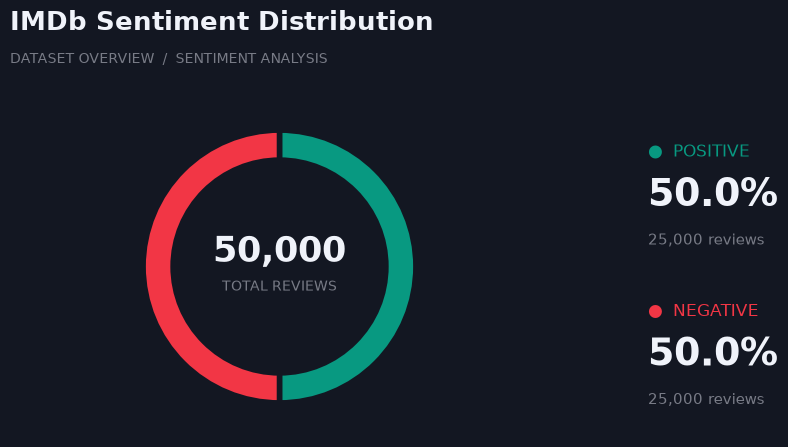

In [38]:
counts = df["sentiment"].value_counts()
positive = counts.get("positive", 0)
negative = counts.get("negative", 0)
total = positive + negative

bg = "#131722"
green = "#089981"
red = "#F23645"
white = "#F0F3FA"
gray = "#787B86"

fig = plt.figure(figsize=(11, 5.5), facecolor=bg)

fig.text(
    0.07, 0.88,
    "IMDb Sentiment Distribution",
    color=white, fontsize=19, fontweight="bold"
)

fig.text(
    0.07, 0.82,
    "DATASET OVERVIEW  /  SENTIMENT ANALYSIS",
    color=gray, fontsize=10
)

ax = fig.add_axes((0.08, 0.14, 0.47, 0.62))
ax.set_facecolor(bg)

ax.pie(
    [positive, negative],
    colors=[green, red],
    startangle=90,
    counterclock=False,
    wedgeprops={
        "width": 0.22,
        "edgecolor": bg,
        "linewidth": 4
    }
)

ax.text(
    0, 0.10, f"{total:,}",
    ha="center", va="center",
    fontsize=25, fontweight="bold", color=white
)

ax.text(
    0, -0.15, "TOTAL REVIEWS",
    ha="center", va="center",
    fontsize=10, color=gray
)

fig.text(0.65, 0.65, "●  POSITIVE", color=green, fontsize=12)
fig.text(
    0.65, 0.56,
    f"{positive / total * 100:.1f}%",
    color=white, fontsize=27, fontweight="bold"
)
fig.text(0.65, 0.49, f"{positive:,} reviews", color=gray, fontsize=11)

fig.text(0.65, 0.36, "●  NEGATIVE", color=red, fontsize=12)
fig.text(
    0.65, 0.27,
    f"{negative / total * 100:.1f}%",
    color=white, fontsize=27, fontweight="bold"
)
fig.text(0.65, 0.20, f"{negative:,} reviews", color=gray, fontsize=11)

plt.show()

In [11]:
class_counts = df["sentiment"].value_counts()

class_percentages = (
    df["sentiment"].value_counts(normalize=True) * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

class_distribution

,Count,Percentage (%)
sentiment,,
positive,25000,50.0
negative,25000,50.0


In [24]:
df["word_count"] = df["review"].str.split().str.len()
df["word_count"].describe()

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: word_count, dtype: float64

In [25]:
html_mask = df["review"].str.contains(
    r"<[^>]+>",
    regex=True,
    na=False
)

html_count = html_mask.sum()

print(f"Reviews containing HTML tags: {html_count:,}")
print(f"Percentage: {html_count / len(df) * 100:.2f}%")

Reviews containing HTML tags: 29,202
Percentage: 58.40%


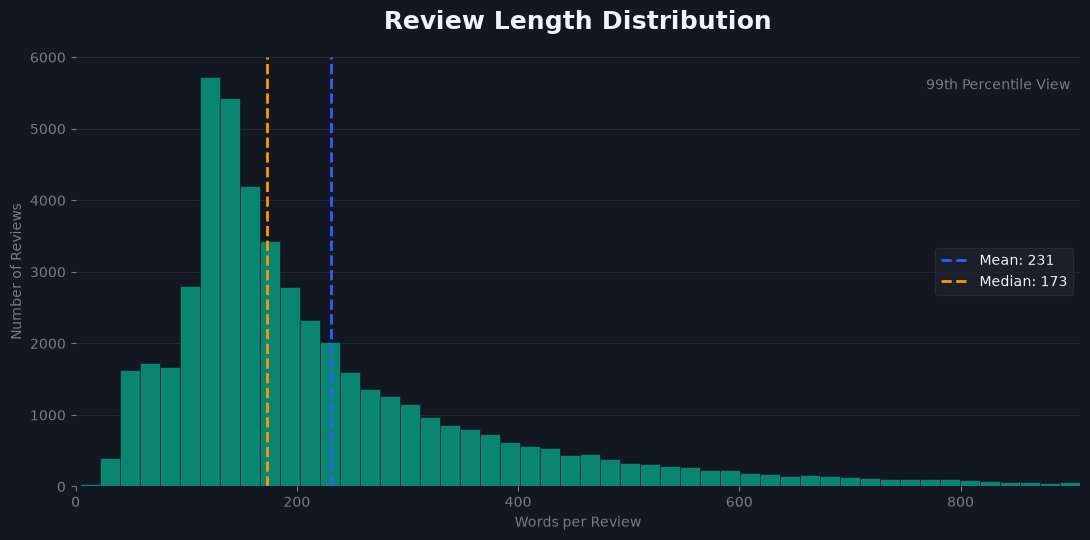

In [39]:
data = df["word_count"].dropna()

mean_val = data.mean()
median_val = data.median()
upper_limit = data.quantile(0.99)

bg = "#131722"
green = "#089981"
blue = "#2962FF"
orange = "#FF9800"
white = "#F0F3FA"
gray = "#787B86"

fig, ax = plt.subplots(figsize=(11, 5.5))
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

filtered = data[data <= upper_limit]

ax.hist(
    filtered,
    bins=50,
    color=green,
    alpha=0.85,
    edgecolor=bg,
    linewidth=0.5
)

ax.axvline(
    mean_val, color=blue,
    linestyle="--", linewidth=2,
    label=f"Mean: {mean_val:.0f}"
)

ax.axvline(
    median_val, color=orange,
    linestyle="--", linewidth=2,
    label=f"Median: {median_val:.0f}"
)

ax.set_title(
    "Review Length Distribution",
    color=white, fontsize=18,
    fontweight="bold", pad=20
)

ax.set_xlabel("Words per Review", color=gray)
ax.set_ylabel("Number of Reviews", color=gray)

ax.set_xlim(0, upper_limit)
ax.tick_params(colors=gray)

ax.grid(axis="y", color="#2A2E39", alpha=0.7)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(
    facecolor="#1E222D",
    edgecolor="#2A2E39",
    labelcolor=white
)

ax.text(
    0.99, 0.95,
    "99th Percentile View",
    transform=ax.transAxes,
    ha="right", va="top",
    color=gray, fontsize=10
)

plt.tight_layout()
plt.show()

### 2.1. Анализ на най-често срещаните думи

Изследва се честотата на срещане на думите в текстовите ревюта.

За целта се извършва базова текстова обработка, включваща:

- Премахване на HTML тагове.
- Преобразуване на текста в малки букви.
- Разделяне на текста на отделни думи (Tokenization).
- Изключване на често срещани служебни думи (Stop Words) от визуализацията.

Представят се 20-те най-често срещани думи в набора от данни.

Анализът позволява да се установят основните езикови характеристики на ревютата и най-често използваните понятия.

In [35]:
def tokenize_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)

all_words = Counter()
positive_words = Counter()
negative_words = Counter()

for review, sentiment in zip(df["review"], df["sentiment"]):
    tokens = tokenize_text(review)

    all_words.update(tokens)

    if sentiment == "positive":
        positive_words.update(tokens)
    elif sentiment == "negative":
        negative_words.update(tokens)

stop_words = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "never", "nor"
}

def filter_words(counter):
    return Counter({
        word: count
        for word, count in counter.items()
        if word not in stop_words and len(word) >= 3
    })

filtered_words = filter_words(all_words)

top_20 = filtered_words.most_common(20)

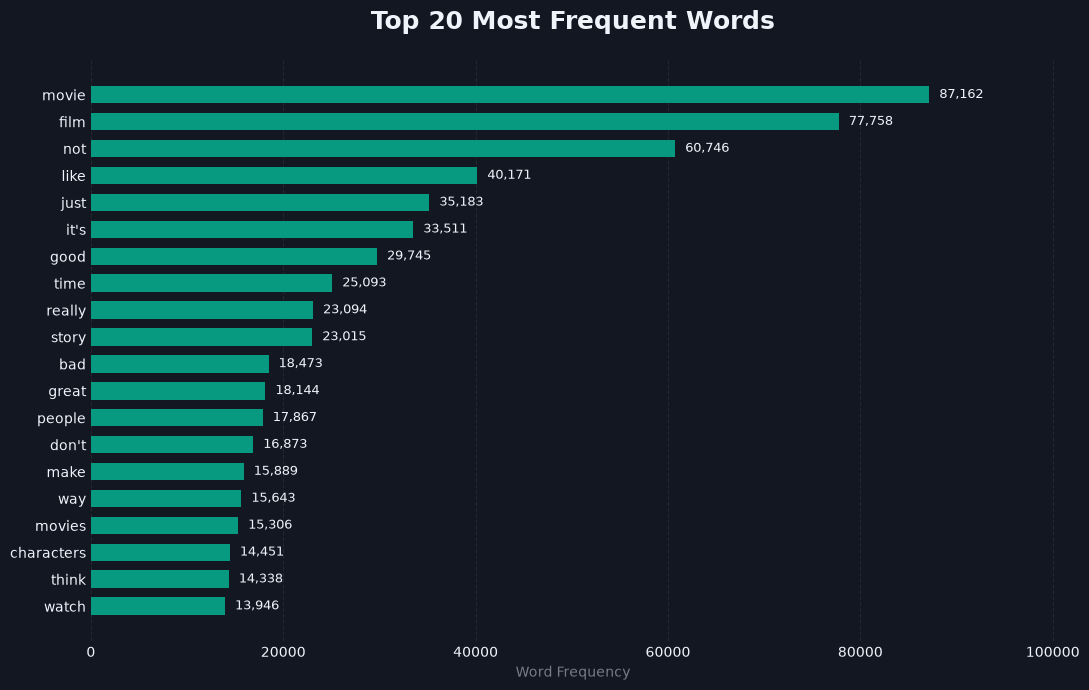

In [37]:
bg = "#131722"
green = "#089981"
white = "#F0F3FA"
gray = "#787B86"
grid = "#2A2E39"

words, frequencies = zip(*top_20)

fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

bars = ax.barh(
    words[::-1],
    frequencies[::-1],
    color=green,
    height=0.65
)

ax.set_title(
    "Top 20 Most Frequent Words",
    color=white, fontsize=18,
    fontweight="bold", pad=22
)

ax.set_xlabel("Word Frequency", color=gray)
ax.tick_params(colors=white, length=0)

ax.grid(axis="x", color=grid, linestyle="--", alpha=0.7)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlim(0, max(frequencies) * 1.15)

for bar in bars:
    ax.text(
        bar.get_width() + max(frequencies) * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center", color=white, fontsize=9
    )

plt.tight_layout()
plt.show()

### 2.2. Анализ на честотата на думите според настроението

Изследват се най-често срещаните думи поотделно в положителните и отрицателните ревюта.

Целта е да се установят различията в използваната лексика между двата класа.

За всеки клас се извеждат 15-те най-често срещани думи след изключване на служебните думи от визуализацията.

Резултатите позволяват да се сравнят езиковите характеристики на положителните и отрицателните мнения и да се идентифицират потенциално значими думи за задачата за класификация.

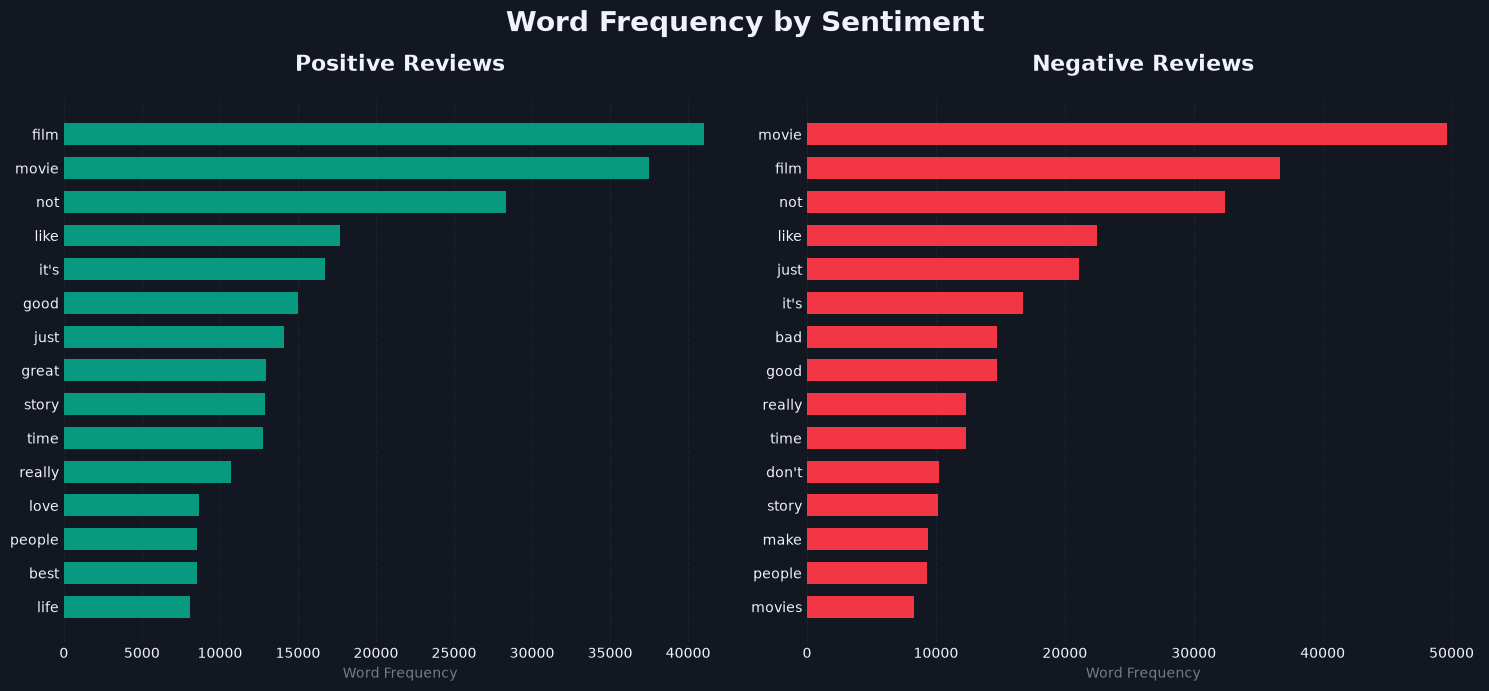

In [33]:
pos_filtered = filter_words(positive_words)
neg_filtered = filter_words(negative_words)

top_pos = pos_filtered.most_common(15)
top_neg = neg_filtered.most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.patch.set_facecolor(bg)

datasets = [
    (top_pos, "Positive Reviews", "#089981"),
    (top_neg, "Negative Reviews", "#F23645")
]

for ax, (data, title, color) in zip(axes, datasets):

    words, counts = zip(*data)

    ax.set_facecolor(bg)

    ax.barh(
        words[::-1],
        counts[::-1],
        color=color,
        height=0.65
    )

    ax.set_title(
        title,
        color=white,
        fontsize=16,
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel("Word Frequency", color=gray)
    ax.tick_params(colors=white, length=0)

    ax.grid(axis="x", color=grid, linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Word Frequency by Sentiment",
    color=white,
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 2.3. Анализ на размера на речника (Vocabulary Size)

Размерът на речника представлява броят на уникалните думи в набора от данни.

Изчисляват се:

- Общият брой уникални думи.
- Броят уникални думи в положителните ревюта.
- Броят уникални думи в отрицателните ревюта.
- Броят думи, които се срещат и в двата класа.
- Броят думи, специфични за всеки клас.

За този анализ се използват всички токенизирани думи, без премахване на Stop Words.

Полученият размер на речника ще послужи като начална стойност (Baseline) за последващото сравнение с алгоритмите Snowball и Lancaster.

Очаква се стемингът да намали броя на уникалните текстови форми чрез обединяване на различни форми на думите.

In [41]:
vocab_all = set(all_words.keys())
vocab_pos = set(positive_words.keys())
vocab_neg = set(negative_words.keys())

total_unique = len(vocab_all)
pos_unique = len(vocab_pos)
neg_unique = len(vocab_neg)

shared = len(vocab_pos & vocab_neg)
pos_only = len(vocab_pos - vocab_neg)
neg_only = len(vocab_neg - vocab_pos)

vocab_stats = pd.DataFrame({
    "Metric": [
        "Total Unique Words",
        "Positive Vocabulary",
        "Negative Vocabulary",
        "Shared Words",
        "Positive Only",
        "Negative Only"
    ],
    "Count": [
        total_unique,
        pos_unique,
        neg_unique,
        shared,
        pos_only,
        neg_only
    ]
})

vocab_stats

,Metric,Count
0,Total Unique Words,109526
1,Positive Vocabulary,81178
2,Negative Vocabulary,77266
3,Shared Words,48918
4,Positive Only,32260
5,Negative Only,28348


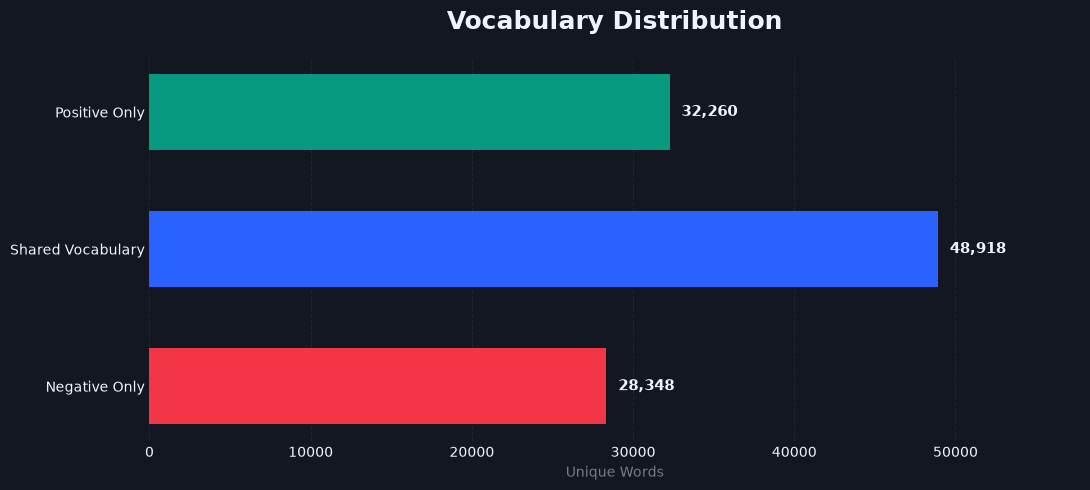

In [42]:
labels = [
    "Positive Only",
    "Shared Vocabulary",
    "Negative Only"
]

values = [pos_only, shared, neg_only]
colors = ["#089981", "#2962FF", "#F23645"]

fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor(bg)
ax.set_facecolor(bg)

bars = ax.barh(
    labels,
    values,
    color=colors,
    height=0.55
)

ax.invert_yaxis()

ax.set_title(
    "Vocabulary Distribution",
    fontsize=18,
    color=white,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Unique Words", color=gray)
ax.tick_params(colors=white, length=0)

ax.grid(axis="x", color=grid, linestyle="--", alpha=0.6)
ax.set_axisbelow(True)

ax.set_xlim(0, max(values) * 1.18)

for bar in bars:
    ax.text(
        bar.get_width() + max(values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center",
        color=white,
        fontsize=11,
        fontweight="bold"
    )

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### Заключение от изследователския анализ

Извършеният изследователски анализ предоставя информация за структурата, качеството и езиковите характеристики на набора от данни IMDb.

Основните направления на анализа включват:

1. Проверка на структурата, липсващите стойности и дублираните записи.
2. Изследване на разпределението на класовете.
3. Анализ на дължината на текстовите ревюта.
4. Установяване на наличието на HTML тагове.
5. Идентифициране на най-често срещаните думи.
6. Сравнение на честотата на думите според настроението.
7. Определяне на размера и структурата на речника.

Резултатите ще бъдат използвани за подготовката на текстовите данни и последващото сравнително изследване на алгоритмите Snowball и Lancaster.